# Mendeley

## Project Description

### Goal:
- build a simple


###  Data Pre-processing (10%)
- Missing values / outliers : Robust and nuanced approach
- Categorical encoding : Advanced or balanced encoding strategies
- Scaling numerical features : Method adapted to model needs

### Feature Selection and Creation (5%)
- Relevant feature selection : Justified selection using data or domain logic Optimal features chosen via analysis
- Feature transformation / creation (Optional depending on the necessity) : Useful engineered features Innovative and insightful feature creation.

### Model Comparison and Hyperparameter Selection (25%)
- Dataset splitting : train/val/test split and crossvalidation
- Model training : more than 3 models tested (among which one deep learning model) with choice justification.
- Performance comparison : In-depth multi-metric evaluation
- Hyperparameter selection/tuning : Advanced tuning with crossvalidation
- Over/underfitting analysis : Correct analysis with remedies, Deep, justified understanding

### Presentation of Results (20%)


### Report :
- EDA requires multiple graphs to be complete.
- When evaluating your failure prediction model, use a baseline (for example, the naive average of the students’ grades). This allows you to compare your model with a very simple ”worst-case” model and determine whether your approach performs better.


## 1. Setup & Imports:

In [32]:
import pickle
import sys
from pathlib import Path

# Third-party
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paths 
PROJECT_ROOT = Path("..").resolve()
DATA_DIR     = PROJECT_ROOT / "datasets" / "mendeley" / "Datasets"
STORE_DIR    = PROJECT_ROOT / "datasets" / "processed"
STORE_DIR.mkdir(parents=True, exist_ok=True)




datasets = {}

def save_datasets(name="datasets.pkl"):
    path = STORE_DIR / name
    with open(path, "wb") as f:
        pickle.dump(datasets, f)
    print(f"saved → {path}  ({path.stat().st_size / 1024**2:.2f} MB)")

def load_datasets(name="datasets.pkl"):
    with open(STORE_DIR / name, "rb") as f:
        return pickle.load(f)

print("Python:", sys.executable)
print("Data:  ", DATA_DIR, "exists:", DATA_DIR.exists())
print("Store: ", STORE_DIR)

Python: /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/fedora-venv/bin/python
Data:   /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/mendeley/Datasets exists: True
Store:  /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed


### Load CSV

In [36]:
iot_train = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_training.csv")
iot_test  = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_testing.csv")

print(f"train shape: {iot_train.shape}  (no label column expected)")
print(f"test  shape: {iot_test.shape}   (label + taxonomy columns present)")
print(f"\ntrain columns: {len(iot_train.columns)}")
print(f"test  columns: {len(iot_test.columns)}")

train shape: (30000, 43)  (no label column expected)
test  shape: (10000, 46)   (label + taxonomy columns present)

train columns: 43
test  columns: 46


## 2. Data Exploration

### 2.1 Raw Data Overview

We start by inspecting the raw dataset before making any preprocessing decisions. This is important because it lets us understand the original structure of the data and identify possible issues such as missing values, identifiers, and variable types.

In [33]:
iot_train = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_training.csv")
print("shape:", iot_train.shape)
print("\ndtypes:\n", iot_train.dtypes.value_counts())
# iot_train.head()


label_cols = [c for c in iot_test.columns if c not in iot_train.columns]
print("Label-related columns present only in test:")
for c in label_cols:
    print(f"  {c:15s} dtype={iot_test[c].dtype}  nunique={iot_test[c].nunique()}")

shape: (30000, 43)

dtypes:
 int64      30
str         7
float64     6
Name: count, dtype: int64
Label-related columns present only in test:
  attack          dtype=int64  nunique=2
  category        dtype=str  nunique=5
  subcategory     dtype=str  nunique=7


#### Check data balance

- `io_train` : ONLY benign traffic. Model learn what normal traffic looks like.
- `io_test` : 50/50 attack and benign. 

-> Test set has 3 more columns than train.

In [13]:
iot_test = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_testing.csv")
pc_test  = pd.read_csv(DATA_DIR / "PCs_devices_dataset_for_testing.csv")

for name, df in [("IoT test", iot_test), ("PC test", pc_test)]:
    label_col = [c for c in df.columns if c.lower() in ("attack", "label", "class")][0]
    print(f"\n{name}: {df.shape}, label column = '{label_col}'")
    print(df[label_col].value_counts(dropna=False))


IoT test: (10000, 46), label column = 'attack'
attack
0    5000
1    5000
Name: count, dtype: int64

PC test: (9883, 46), label column = 'attack'
attack
0    9883
Name: count, dtype: int64


#### Feature overview and missing values

In [16]:
raw_X = datasets["raw"]["X_train"]

summary = pd.DataFrame({
    "column": raw_X.columns,
    "dtype": [raw_X[col].dtype for col in raw_X.columns],
    "missing_values": [raw_X[col].isna().sum() for col in raw_X.columns],
    "mean": [
        raw_X[col].mean() if pd.api.types.is_numeric_dtype(raw_X[col]) else None
        for col in raw_X.columns
    ],
    "sample_values": [
        raw_X[col].dropna().unique()[:5] for col in raw_X.columns
    ],
    "cardinality": [raw_X[col].nunique() for col in raw_X.columns],

})

display(summary)


# summary = pd.DataFrame({
#     "dtype": iot_train.dtypes,
#     "n_missing": iot_train.isna().sum(),
#     "n_unique": iot_train.nunique(),
#     "min": iot_train.select_dtypes("number").min(),
#     "max": iot_train.select_dtypes("number").max(),
# })
# summary

,column,dtype,missing_values,mean,sample_values,cardinality
0,pkSeqID,int64,0,15000.500000,"[1, 2, 3, 4, 5]",30000
1,stime,str,0,NaN,[2025-06-07 10:36:17],1
2,flgs,str,0,NaN,"[PA, U]",2
3,flgs_number,int64,0,1.000000,[1],1
4,proto,str,0,NaN,"[SMB, NTP, HTTPS, HTTP, DNS]",9
5,proto_number,int64,0,10.853200,"[6, 17]",2
6,saddr,str,0,NaN,"[192.168.100.11, 192.168.100.12, 192.168.100.1...",6
7,sport,int64,0,33149.807600,"[63010, 60765, 5369, 61780, 37984]",23970
8,daddr,str,0,NaN,"[192.168.100.20, 192.168.100.216, 192.168.100....",348
9,dport,int64,0,705.444833,"[445, 123, 443, 80, 139]",10


### Overview :

#### Group A - constants : 
- `AR_P_Proto_P_Dport` to `TnP_Per_Dport` (19 first rows).
- Also : `flgs_number`(numeric encoding of flgs), `state`, `state_number`, `stime`, `ltime`,
- Constant values
- not useful, dropped.


#### Group B -identifiers :
- `pkSeqID` and `seq`.
- Both are just row indices. Including them would let the model memorise row order rather than learn traffic structure. This is a classic data leakage trap.


#### Group C — High-cardinality categoricals :
- `saddr` : 6 source IPs — probably the 6 testbed devices.
- `daddr` :	348 destination IPs. Too many to one-hot, and they carry almost no generalisable signal.
- `sport` :	23,970 Source Ports. Drop or bucket. Almost every row has a unique source port (ephemeral ports). Bucket into ranges or drop.
- `flgs`  :	Only PA and U in the sample. Use the 2-value string; ignore the broken flgs_number.
- `proto` :	9 protocols (SMB, NTP, HTTPS, HTTP, etc.). One-hot into 9 features, or use proto_number (2 unique values = TCP 6 / UDP 17).


#### Group D — Redundant pairs, keep one of each.
- `sbytes` / `dbytes` : Both n_unique=2351, both min=150, max=2500	Identical distributions. Drop one.
- `spkts` / `dpkts`	: Both n_unique=24, both 2–25	Drop one.
- `srate` / `drate`	: Both n_unique=28268	Drop one.
- `bytes` = `sbytes` + `dbytes` (roughly)	bytes 300–5000, sbytes 150–2500	Keep bytes, drop the two components.

This symmetry is not accidental — it is a strong sign the dataset was synthetically constructed with mirrored source/destination features. Useful for smoke-testing a Flower pipeline, less realistic as intrusion data.


#### Group E — Genuinely informative features :
- `bytes` :	300–5000	total bytes in the flow
- `pkts` :	5–50	total packets in the flow
- `dur` :	0.1–2.5 s	flow duration
- `rate` :	123–48,765	packets per second
- `mean` :	6–1000	mean duration of aggregated sub-flows
- `min` :	40–60	minimum sub-flow duration
- `max` :	500–1000	maximum sub-flow duration
- `stddev` :	0.1–1.5	std-dev of sub-flow durations — 30,000 unique values, looks like noise
- `sum` :	300–5000	sum of sub-flow durations (highly correlated with bytes)
- `proto_number` :	6 or 17	TCP vs. UDP
- `dport` :	10 values	destination port (53, 80, 443, 445, 5683, …)
- `flgs` :	2 values	flow flags (PA, U)

-> those 10–14 features actually carry variation.
--> That gives you roughly 10–12 useful numeric features and 2 low-cardinality categoricals (proto, flgs, or use proto_number + dport and skip flgs).


#### Note :
- stime has n_unique = 1. Every row in the training file shares the same start timestamp.
- Either the training file is a very short capture, or data was synthetically generated or post-processed.
- This dataset has no temporal signal in the training split.
- This dataset can only be used as a smoke test for our Flower pipeline, not a realistic benchmark




### Save Raw Dataset

In [ ]:
LABEL_COLS = ["attack", "category", "subcategory"]

datasets["raw"] = {
    "X_train": iot_train.copy(),
    "X_test":  iot_test.drop(columns=LABEL_COLS).copy(),
    "y_test":  iot_test["attack"].copy(),
    "description": "Raw: unlabeled train; test with target+taxonomy dropped",
}

# Compare train and test column names and their order
assert list(datasets["raw"]["X_train"].columns) == list(datasets["raw"]["X_test"].columns), \
    "raw train/test columns must match"

for k, v in datasets["raw"].items():
    if hasattr(v, "shape"):
        print(f"  {k:10s} {v.shape}")

save_datasets()

  X_train    (30000, 43)
  X_test     (10000, 43)
  y_test     (10000,)
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (16.17 MB)


### Feature selection - Cleaned dataset

In [38]:
CONSTANT_COLS = [c for c in iot_train.columns if iot_train[c].nunique() <= 1]
ID_COLS       = ["pkSeqID", "seq"]
HIGH_CARD     = ["saddr", "daddr", "sport"]
REDUNDANT     = ["sbytes", "dbytes", "spkts", "dpkts", "srate"]
DROP          = CONSTANT_COLS + ID_COLS + HIGH_CARD + REDUNDANT

datasets["cleaned"] = {
    "train_X": datasets["raw"]["X_train"].drop(columns=DROP, errors="ignore").copy(),
    "test_X":  datasets["raw"]["X_test"].drop(columns=DROP, errors="ignore").copy(),
    "test_y":  datasets["raw"]["y_test"].copy(),
    "description": "Cleaned: constants/IDs/high-card/redundant dropped",
}

assert list(datasets["cleaned"]["train_X"].columns) == list(datasets["cleaned"]["test_X"].columns), \
    "cleaned train/test columns must match"

print(f"Dropped {len(DROP)} columns; kept {datasets['cleaned']['train_X'].shape[1]}")
print(f"Kept: {datasets['cleaned']['train_X'].columns.tolist()}")
for k, v in datasets["cleaned"].items():
    if hasattr(v, "shape"):
        print(f"  {k:10s} {v.shape}")

save_datasets()

Dropped 28 columns; kept 15
Kept: ['flgs', 'proto', 'proto_number', 'dport', 'pkts', 'bytes', 'ltime', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'rate', 'drate']
  train_X    (30000, 15)
  test_X     (10000, 15)
  test_y     (10000,)
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (16.17 MB)


### 2.3. EDA plots on raw data

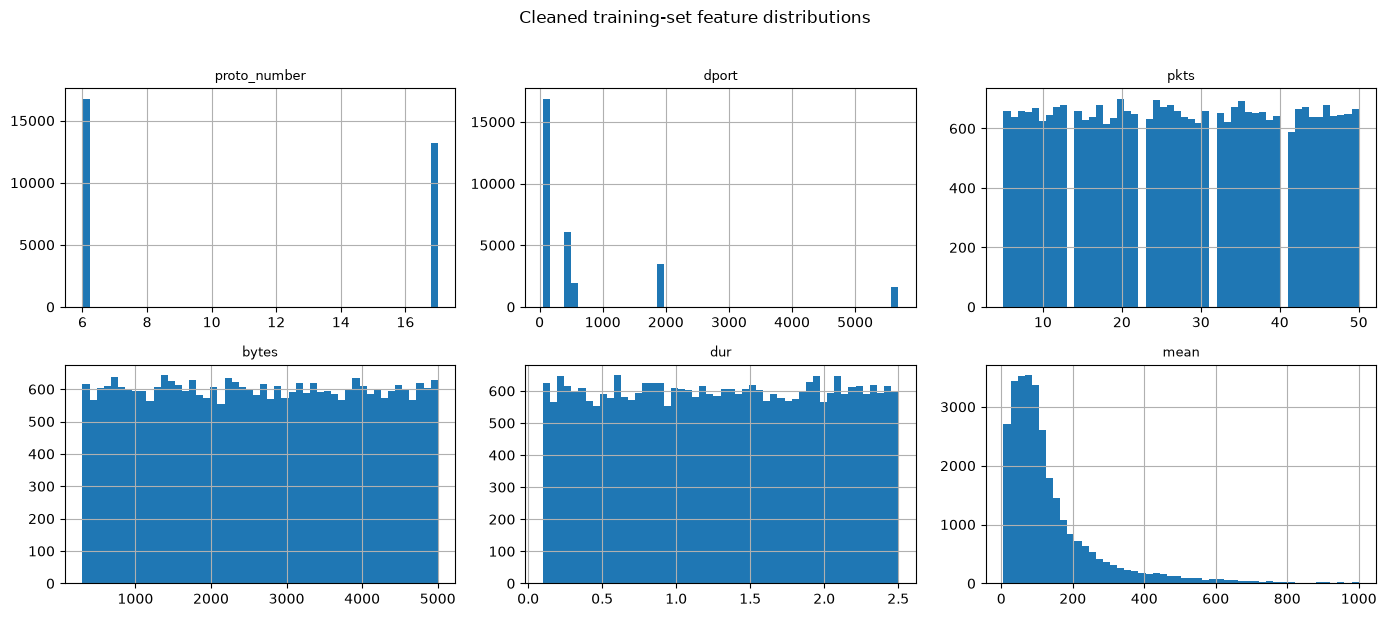

In [41]:
# ----- Distribution histograms -------
train_X = datasets["cleaned"]["train_X"]
num_cols = train_X.select_dtypes("number").columns.tolist()
to_plot = num_cols[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), to_plot):
    train_X[col].hist(ax=ax, bins=50)
    ax.set_title(col, fontsize=9)
plt.suptitle("Cleaned training-set feature distributions", y=1.02)
plt.tight_layout()
plt.show()

#### Compare feature distributions: training (benign-dominant) vs. testing (labeled)

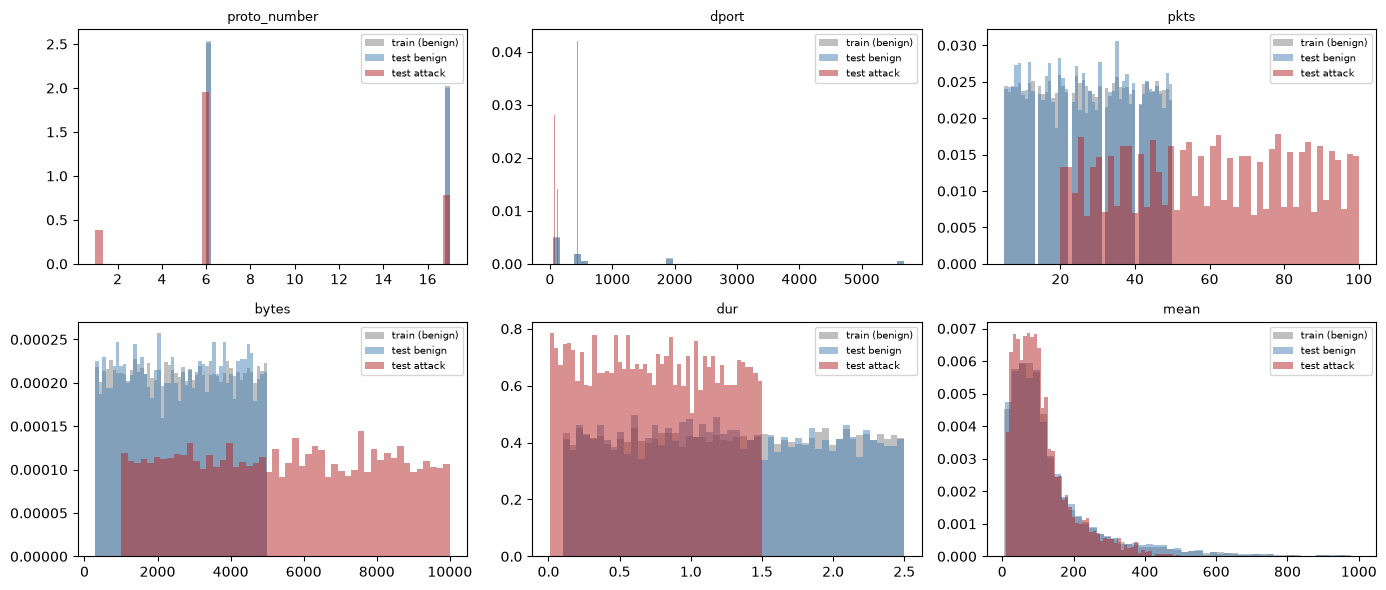

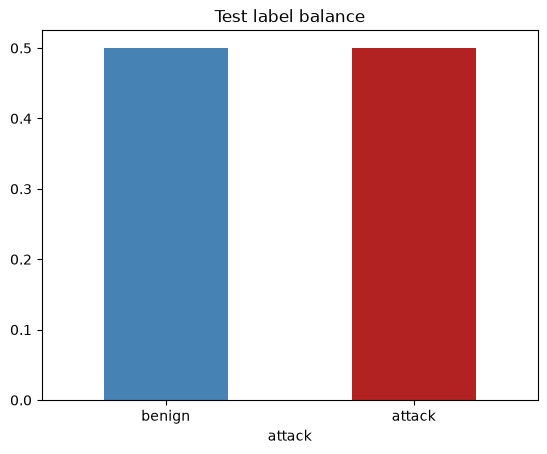

In [42]:
test_X = datasets["cleaned"]["test_X"]
y_test = datasets["cleaned"]["test_y"]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), to_plot):
    ax.hist(train_X[col], bins=50, alpha=0.5, label="train (benign)",
            density=True, color="grey")
    ax.hist(test_X.loc[y_test == 0, col], bins=50, alpha=0.5, label="test benign",
            density=True, color="steelblue")
    ax.hist(test_X.loc[y_test == 1, col], bins=50, alpha=0.5, label="test attack",
            density=True, color="firebrick")
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

y_test.value_counts(normalize=True).plot(
    kind="bar", title="Test label balance", color=["steelblue", "firebrick"]
)
plt.xticks([0, 1], ["benign", "attack"], rotation=0)
plt.show()

#### Pytorch dataset

In [43]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Preliminary numeric-only check. The real model input after encoding
# will include one-hot features and have a slightly wider shape.
X_num = datasets["cleaned"]["train_X"].select_dtypes("number").to_numpy(dtype=np.float32)
X_num = np.nan_to_num(X_num)

X_t = torch.from_numpy(X_num)
print("tensor shape:", X_t.shape, "dtype:", X_t.dtype)

loader = DataLoader(TensorDataset(X_t), batch_size=256, shuffle=True)
batch = next(iter(loader))
print("one batch:", batch[0].shape)

tensor shape: torch.Size([30000, 12]) dtype: torch.float32
one batch: torch.Size([256, 12])


## 3. Preprocessing

### 3.1 Dataset Splitting

In [ ]:
from sklearn.model_selection import train_test_split

X_tr, X_val = train_test_split(
    datasets["cleaned"]["train_X"],
    train_size=0.9, 
    test_size=0.1,
    random_state=42,
)
print(f"train: {X_tr.shape}   valid: {X_val.shape}")

train: (27000, 15)   valid: (3000, 15)


### 3.2 Semi-supervised dataset

In [45]:
datasets["semisup"] = {
    "X_train": X_tr.copy(),                                # benign, training
    "X_valid": X_val.copy(),                               # benign, threshold
    "X_test":  datasets["cleaned"]["test_X"].copy(),       # mixed
    "y_test":  datasets["cleaned"]["test_y"].copy(),       # 0/1
    "description": "Semi-supervised: benign train/valid, mixed labeled test",
}

assert list(datasets["semisup"]["X_train"].columns) == \
       list(datasets["semisup"]["X_test"].columns), \
    "semisup train/test columns must match"

for name, contents in datasets.items():
    print(f"\n=== {name} ===")
    for k, v in contents.items():
        if hasattr(v, "shape"):
            print(f"  {k:10s} {v.shape}")

save_datasets()


=== raw ===
  X_train    (30000, 43)
  X_test     (10000, 43)
  y_test     (10000,)

=== cleaned ===
  train_X    (30000, 15)
  test_X     (10000, 15)
  test_y     (10000,)

=== semisup ===
  X_train    (27000, 15)
  X_valid    (3000, 15)
  X_test     (10000, 15)
  y_test     (10000,)
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (20.53 MB)


## 4. Encoding


- Categorical columns → one-hot (`handle_unknown="ignore"`).
- Numeric columns → `StandardScaler`.
- Both fit on **train only**, applied to valid and test.

In [46]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_tr = datasets["semisup"]["X_train"]
X_va = datasets["semisup"]["X_valid"]
X_te = datasets["semisup"]["X_test"]

cat_cols = X_tr.select_dtypes("object").columns.tolist()
num_cols = [c for c in X_tr.columns if c not in cat_cols]
print(f"categorical: {cat_cols}")
print(f"numeric:     {num_cols}")

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
tr_cat = ohe.fit_transform(X_tr[cat_cols])
va_cat = ohe.transform(X_va[cat_cols])
te_cat = ohe.transform(X_te[cat_cols])

tr_enc = np.hstack([X_tr[num_cols].to_numpy(np.float32), tr_cat]).astype(np.float32)
va_enc = np.hstack([X_va[num_cols].to_numpy(np.float32), va_cat]).astype(np.float32)
te_enc = np.hstack([X_te[num_cols].to_numpy(np.float32), te_cat]).astype(np.float32)

scaler = StandardScaler().fit(tr_enc)

datasets["encoded"] = {
    "X_train": scaler.transform(tr_enc).astype(np.float32),
    "X_valid": scaler.transform(va_enc).astype(np.float32),
    "X_test":  scaler.transform(te_enc).astype(np.float32),
    "y_test":  datasets["semisup"]["y_test"].to_numpy(),
    "feature_names": num_cols + ohe.get_feature_names_out(cat_cols).tolist(),
    "encoder": ohe,
    "scaler":  scaler,
    "description": "One-hot + standard-scale, fit on benign train",
}

for k, v in datasets["encoded"].items():
    if hasattr(v, "shape"):
        print(f"  {k:10s} {v.shape}")
print(f"features ({len(datasets['encoded']['feature_names'])}): "
      f"{datasets['encoded']['feature_names']}")

save_datasets()

categorical: ['flgs', 'proto', 'ltime']
numeric:     ['proto_number', 'dport', 'pkts', 'bytes', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'rate', 'drate']
  X_train    (27000, 26)
  X_valid    (3000, 26)
  X_test     (10000, 26)
  y_test     (10000,)
features (26): ['proto_number', 'dport', 'pkts', 'bytes', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'rate', 'drate', 'flgs_PA', 'flgs_U', 'proto_CoAP', 'proto_DNS', 'proto_HTTP', 'proto_HTTPS', 'proto_MQTT', 'proto_NTP', 'proto_RTSP', 'proto_SMB', 'proto_SSDP', 'ltime_2025-06-07 10:36:18', 'ltime_2025-06-07 10:36:19', 'ltime_2025-06-07 10:36:20']
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.57 MB)


/tmp/ipykernel_1435119/3299023002.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_tr.select_dtypes("object").columns.tolist()


## 5. Autoencoder

#### Why AE ?
The training set is 100% benign. So the autoencoder learns the structure of normal traffic and only normal traffic. At inference:
- A benign flow comes in → matches the structure the model learned → low reconstruction error.
- An attack flow comes in → doesn't match any benign pattern → the model can't encode it → high reconstruction error.


Small symmetric autoencoder:
- input: encoded feature width (d~20)
- bottleneck: 4
- trained with MSE on benign training data

epoch   0  train=1.00696  valid=0.95987
epoch   5  train=0.66370  valid=0.65474
epoch  10  train=0.56981  valid=0.55602
epoch  15  train=0.49443  valid=0.48634
epoch  20  train=0.47183  valid=0.46450
epoch  25  train=0.45324  valid=0.44696
epoch  30  train=0.43741  valid=0.43247
epoch  35  train=0.42885  valid=0.42386
epoch  40  train=0.42389  valid=0.42210
epoch  45  train=0.42046  valid=0.41613
epoch  50  train=0.41781  valid=0.41544
epoch  55  train=0.41595  valid=0.41330
epoch  60  train=0.41405  valid=0.41171
epoch  65  train=0.41162  valid=0.40898
epoch  70  train=0.41021  valid=0.40701
epoch  75  train=0.40910  valid=0.40672
epoch  80  train=0.40766  valid=0.40510
epoch  85  train=0.40676  valid=0.40416
epoch  90  train=0.40535  valid=0.40356
epoch  95  train=0.40422  valid=0.40175
epoch  99  train=0.40259  valid=0.39829


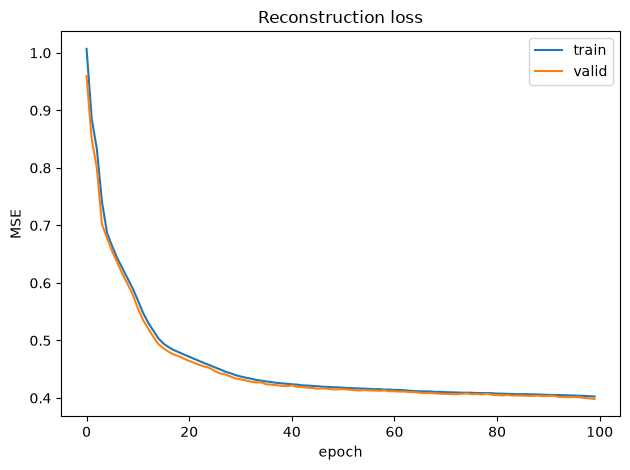

saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.58 MB)


In [49]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

class Autoencoder(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, 16), nn.ReLU(),    # Dimension halves each step
            nn.Linear(16, 8),      nn.ReLU(),    # forces compression
            nn.Linear(8, 4),       nn.ReLU(),
        )
        self.decoder = nn.Sequential(           # Bottleneck : 4 dimensions. 20 features squeezed into 4 numbers.
            nn.Linear(4, 8),       nn.ReLU(),
            nn.Linear(8, 16),      nn.ReLU(),
            nn.Linear(16, in_dim),
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

# Load
X_tr = datasets["encoded"]["X_train"]
X_va = datasets["encoded"]["X_valid"]

model     = Autoencoder(X_tr.shape[1])
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)  # Use adam as default
loss_fn   = nn.MSELoss()                                   # use MSE loss

loader = DataLoader(
    TensorDataset(torch.from_numpy(X_tr)),       # Used for batching.
    batch_size=256, 
    shuffle=True
)
X_va_t = torch.from_numpy(X_va)




# ------------------- Training -----------------------
EPOCHS = 100
hist = {"train": [], "valid": []}
best_val, best_state = float("inf"), None

for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for (batch,) in loader:
        optimizer.zero_grad()                 # reset gradients
        loss = loss_fn(model(batch), batch)   # forward pass
        loss.backward()                       # gradient of the loss for each param
        optimizer.step()                        # update params in the step of the Gradient descent.
        running += loss.item() * batch.size(0)  # 
    tr_loss = running / len(loader.dataset)     # clean per-sample average.



    model.eval()          # switch to inference mode
    with torch.no_grad(): 
        va_loss = loss_fn(model(X_va_t), X_va_t).item()  # stop building the computationnal graph

    # Early-stop
    hist["train"].append(tr_loss)
    hist["valid"].append(va_loss)
    if va_loss < best_val:
        best_val, best_state = va_loss, {k: v.clone() for k, v in model.state_dict().items()}

    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch:3d}  train={tr_loss:.5f}  valid={va_loss:.5f}")

model.load_state_dict(best_state)   # restore best model


# Graph
plt.plot(hist["train"], label="train")
plt.plot(hist["valid"], label="valid")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend()
plt.title("Reconstruction loss")
plt.tight_layout(); plt.show()

datasets["autoencoder"] = {"model_state": best_state, "in_dim": X_tr.shape[1], "hist": hist}
save_datasets()

## 6. Threshold & Evaluation

The AE isn't a classifier, it only outputs a reconstruction. What construction error threshold do we choose to determine if we have an "attack" or a "bening" state ?

ex.
```bash
Row 1 (benign):   error = 0.15
Row 2 (attack):   error = 1.80
Row 3 (benign):   error = 0.22
Row 4 (attack):   error = 2.10
Row 5 (benign):   error = 0.08
...
```

What error value is greater than 95% of these?
-> this is the value we'll use.


Threshold = 95th percentile of reconstruction error on benign valid (5% FPR target).
Predict attack if error > threshold.

threshold = 0.96211

Confusion matrix:
[[4753  247]
 [2519 2481]]

Classification report:
              precision    recall  f1-score   support

      benign       0.65      0.95      0.77      5000
      attack       0.91      0.50      0.64      5000

    accuracy                           0.72     10000
   macro avg       0.78      0.72      0.71     10000
weighted avg       0.78      0.72      0.71     10000

ROC-AUC: 0.8608


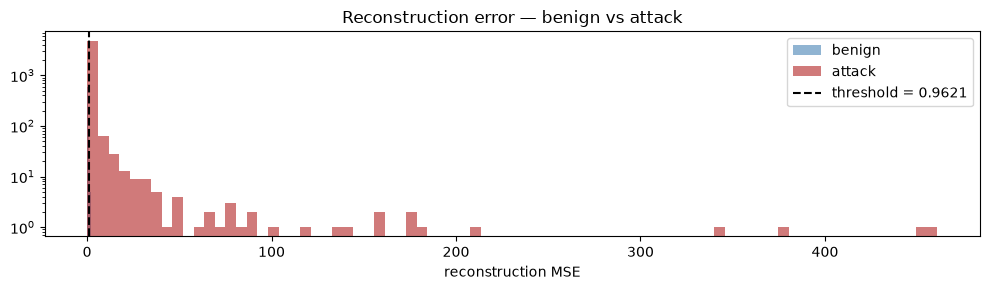

saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.71 MB)


In [48]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

def recon_errors(m, X):
    m.eval()
    with torch.no_grad():
        X_t = torch.from_numpy(X)
        return ((m(X_t) - X_t) ** 2).mean(dim=1).numpy()

val_err  = recon_errors(model, datasets["encoded"]["X_valid"])
test_err = recon_errors(model, datasets["encoded"]["X_test"])

THRESHOLD = np.percentile(val_err, 95)
print(f"threshold = {THRESHOLD:.5f}")

y_test = datasets["encoded"]["y_test"]
y_pred = (test_err > THRESHOLD).astype(int)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["benign", "attack"]))
print(f"ROC-AUC: {roc_auc_score(y_test, test_err):.4f}")

plt.figure(figsize=(10, 3))
plt.hist(test_err[y_test == 0], bins=80, alpha=0.6, label="benign", color="steelblue")
plt.hist(test_err[y_test == 1], bins=80, alpha=0.6, label="attack", color="firebrick")
plt.axvline(THRESHOLD, color="black", linestyle="--", label=f"threshold = {THRESHOLD:.4f}")
plt.yscale("log"); plt.legend(); plt.xlabel("reconstruction MSE")
plt.title("Reconstruction error — benign vs attack")
plt.tight_layout(); plt.show()

datasets["autoencoder"].update({
    "threshold":   THRESHOLD,
    "val_errors":  val_err,
    "test_errors": test_err,
    "test_pred":   y_pred,
})
save_datasets()